# Run 08: leaf cropping and ensemble
Images cropped to the leaf before resizing (single change from Run 05) and an ensemble of three CNNs, on Tomato, Papaya and Bottle Gourd.

## 1. GPU check

In [6]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Settings + Drive

In [7]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q imagehash
from pathlib import Path
import json, time, gc, hashlib, subprocess
import numpy as np, pandas as pd, psutil, imagehash
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

PROJECT   = Path('/content/drive/MyDrive/thesis')
ZIP_PATH  = PROJECT / 'data/raw/agri_vision.zip'
RICE_ZIP  = PROJECT / 'data/raw/riceleafbd.zip'          # <-- must match the rice zip name in Drive
# ===================== SETTINGS (baseline = Tomato Run 01b) =====================
CROPS           = ['Tomato', 'Papaya', 'Bottle_Gourd']  # trained in this order
RUN_NAME        = 'run08_leafcrop'
LEAF_CROP       = True                                  # Run 08: crop every photo to the leaf
LABEL_SMOOTHING = 0.0
TARGET_PER_CLASS = 300                                  # at least 300; raised to the largest class of a crop if bigger
USE_CLASS_WEIGHTS = False
AUGMENT         = 'moderate'
MIXUP_ALPHA     = 0
CUTMIX_ALPHA    = 0
IMG_SIZE        = 224
MODEL_NAMES     = ['VGG16', 'ConvNeXtTiny', 'DenseNet121']
# ================================================================================
FOLD, SEED, N_FOLDS = 0, 42, 5
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
print('Rice zip found:', RICE_ZIP.exists(), '| Agri-Vision zip found:', ZIP_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rice zip found: True | Agri-Vision zip found: True


## 3. Agri-Vision: unzip to local disk

In [8]:
import shutil
UNZIP_DIR = Path('/content/data/agri_vision')
print('Agri-Vision zip found in Drive:', ZIP_PATH.exists(), ZIP_PATH)
assert ZIP_PATH.exists(), 'Zip not found: check the file name and folder in Google Drive'

def find_orig():
    return [p for p in UNZIP_DIR.rglob('*') if p.is_dir() and 'original' in p.name.lower()]

if not find_orig():                      # missing or incomplete unzip -> start again cleanly
    shutil.rmtree(UNZIP_DIR, ignore_errors=True)
    UNZIP_DIR.mkdir(parents=True)
    !unzip -q "{ZIP_PATH}" -d "{UNZIP_DIR}"
    for inner in list(UNZIP_DIR.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

found = find_orig()
if not found:
    print('Still no "Original" folder. Top folders inside the zip:')
    for p in sorted(UNZIP_DIR.rglob('*')):
        if p.is_dir() and len(p.relative_to(UNZIP_DIR).parts) <= 3:
            print('   ', p.relative_to(UNZIP_DIR))
    raise SystemExit('Original images folder not found')
ORIG_DIR = found[0]
print('Original images folder:', ORIG_DIR)

Agri-Vision zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/agri_vision.zip
Original images folder: /content/data/agri_vision/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea/Bottle Gourd, Papaya, Tomato, and Zucchini Original Dataset


## 4. Agri-Vision: audit, clean and folds

In [9]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
rows = []
for p in tqdm(sorted(q for q in ORIG_DIR.rglob('*') if q.suffix.lower() in IMG_EXT), desc='Hashing'):
    parts = p.relative_to(ORIG_DIR).parts
    rec = {'rel_path': '/'.join(parts), 'split': parts[0], 'label_raw': parts[-2]}
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            rec['phash'] = str(imagehash.phash(im.convert('RGB')))
        rec['md5'] = hashlib.md5(p.read_bytes()).hexdigest()
        rec['corrupt'] = False
    except Exception:
        rec['corrupt'] = True
    rows.append(rec)
df = pd.DataFrame(rows).sort_values('rel_path').reset_index(drop=True)
df['label'] = df.label_raw.replace({'Tomato_Downy Mildew': 'Tomato_Downy_Mildew', 'Zucchini_Downy_Midew': 'Zucchini_Downy_Mildew'})
df['crop'] = df.label.str.extract(r'^(Bottle_Gourd|Papaya|Tomato|Zucchini)', expand=False)
df['keep'], df['reason'] = True, ''

def drop(mask, reason):
    m = mask & df.keep
    df.loc[m, 'keep'], df.loc[m, 'reason'] = False, reason
    print(f'{reason:24s} removed {int(m.sum()):5d}   remaining {int(df.keep.sum()):5d}')

drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
drop(df.crop.eq('Zucchini'), 'excluded_zucchini')

kept = df[df.keep].copy()
kept['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(kept, kept.label, groups=kept.phash)):
    kept.iloc[tst, kept.columns.get_loc('fold')] = k
assert kept.md5.is_unique and kept.groupby('phash').fold.nunique().max() == 1
AV_KEPT, AV_DIR = kept, ORIG_DIR
print(kept.groupby('crop').size().rename('clean images').to_string())

Hashing:   0%|          | 0/5246 [00:00<?, ?it/s]

unreadable               removed     0   remaining  5246
label_conflict_exact     removed   754   remaining  4492
duplicate_copy           removed   463   remaining  4029
label_conflict_near      removed    18   remaining  4011
excluded_zucchini        removed   262   remaining  3749
crop
Bottle_Gourd    1491
Papaya          1463
Tomato           795


## 5. RiceLeafBD: unzip, read labels, audit, clean and folds

In [10]:
import shutil
RICE_ROOT = Path('/content/data/riceleafbd')
print('Rice zip found in Drive:', RICE_ZIP.exists(), RICE_ZIP)
assert RICE_ZIP.exists(), 'Rice zip not found: check the file name and folder in Google Drive'
if not RICE_ROOT.exists() or not any(q.suffix.lower() in IMG_EXT for q in RICE_ROOT.rglob('*')):
    shutil.rmtree(RICE_ROOT, ignore_errors=True)
    RICE_ROOT.mkdir(parents=True)
    !unzip -q "{RICE_ZIP}" -d "{RICE_ROOT}"
    for inner in list(RICE_ROOT.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

print('Folder tree (folders with images):')
for p in sorted(q for q in RICE_ROOT.rglob('*') if q.is_dir()):
    n = sum(1 for f in p.iterdir() if f.suffix.lower() in IMG_EXT)
    if n or len(p.relative_to(RICE_ROOT).parts) <= 2:
        print('   ' * (len(p.relative_to(RICE_ROOT).parts) - 1) + f'{p.name}/  ({n} images)')
print('CSV files:', [str(c.relative_to(RICE_ROOT)) for c in RICE_ROOT.rglob('*.csv')])

RICE_CLASSES = [('tungro', 'Rice_Tungro'), ('brown', 'Rice_Brown_Spot'),
                ('bacterial', 'Rice_Bacterial_Leaf_Blight'), ('blight', 'Rice_Bacterial_Leaf_Blight'),
                ('healthy', 'Rice_Healthy')]
def rice_label(text):
    t = str(text).lower().replace('_', ' ').replace('-', ' ')
    for key, lab in RICE_CLASSES:
        if key in t:
            return lab
    return None

files = sorted(q for q in RICE_ROOT.rglob('*') if q.suffix.lower() in IMG_EXT
               and not any('augment' in part.lower() for part in q.relative_to(RICE_ROOT).parts))
r = pd.DataFrame({'rel_path': ['/'.join(q.relative_to(RICE_ROOT).parts) for q in files]})
r['label'] = [next((l for l in (rice_label(x) for x in reversed(q.relative_to(RICE_ROOT).parts[:-1])) if l), None) for q in files]
print(f'\n{len(r)} images found; labelled from folder names: {r.label.notna().sum()}')

if r.label.isna().mean() > 0.5:                                    # folders do not name the classes -> try the CSV
    for c in RICE_ROOT.rglob('*.csv'):
        t = pd.read_csv(c)
        fcol = next((k for k in t.columns if t[k].astype(str).str.lower().str.contains(r'\.(?:jpe?g|png|bmp|webp|tiff?)$').mean() > 0.8), None)
        lcol = next((k for k in t.columns if k != fcol and t[k].map(rice_label).notna().mean() > 0.8), None)
        if fcol and lcol:
            m = dict(zip(t[fcol].astype(str).map(lambda s: Path(s).name), t[lcol].map(rice_label)))
            r['label'] = [m.get(Path(p).name) for p in r.rel_path]
            print(f'Labels taken from {c.name}: file column "{fcol}", label column "{lcol}"; matched {r.label.notna().sum()}')
            break
if r.label.isna().any():
    print('Images WITHOUT a label (skipped):', int(r.label.isna().sum()), r[r.label.isna()].rel_path.head(5).tolist())
r = r[r.label.notna()].reset_index(drop=True)

ph, m5, bad = [], [], []
for p in tqdm(r.rel_path, desc='Hashing rice'):
    try:
        with Image.open(RICE_ROOT / p) as im:
            im.verify()
        with Image.open(RICE_ROOT / p) as im:
            ph.append(str(imagehash.phash(im.convert('RGB')))); bad.append(False)
        m5.append(hashlib.md5((RICE_ROOT / p).read_bytes()).hexdigest())
    except Exception:
        ph.append(None); m5.append(None); bad.append(True)
r['phash'], r['md5'], r['corrupt'], r['crop'] = ph, m5, bad, 'Rice'
r['keep'], r['reason'] = True, ''

print('\nRice cleaning:')
df = r          # drop() from section 4 works on `df`
drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
k_ = df[df.keep]; near = k_[k_.duplicated('phash', keep=False)]
print(f'near-duplicate images kept (same pHash, same label; grouped into one fold): {len(near)}')

paper = pd.Series({'Rice_Healthy': 252, 'Rice_Bacterial_Leaf_Blight': 417, 'Rice_Brown_Spot': 356, 'Rice_Tungro': 530})
audit = pd.DataFrame({'paper': paper, 'found': r.label.value_counts(), 'after cleaning': r[r.keep].label.value_counts()}).fillna(0).astype(int)
audit.loc['Total'] = audit.sum(); display(audit)
(PROJECT / 'audit').mkdir(exist_ok=True)
r.to_csv(PROJECT / 'audit' / 'riceleafbd_files.csv', index=False); audit.to_csv(PROJECT / 'audit' / 'riceleafbd_audit.csv')

RICE_KEPT = r[r.keep].copy()
RICE_KEPT['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(RICE_KEPT, RICE_KEPT.label, groups=RICE_KEPT.phash)):
    RICE_KEPT.iloc[tst, RICE_KEPT.columns.get_loc('fold')] = k
assert RICE_KEPT.groupby('phash').fold.nunique().max() == 1
RICE_OK = RICE_KEPT.label.nunique() == 4 and len(RICE_KEPT) > 500
if not RICE_OK:
    print('\nRice labels look wrong: rice is skipped in this run.')
    CROPS = [c for c in CROPS if c != 'Rice']

Rice zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/riceleafbd.zip
Folder tree (folders with images):
RiceLeafBD A Real-Field Image Dataset for Rice Lea/  (0 images)
   Original Images/  (0 images)
      Bacterial Leaf Blight/  (422 images)
      Brown Spot/  (356 images)
      Healthy Leaf/  (252 images)
      Tungro Virus/  (530 images)
CSV files: []

1560 images found; labelled from folder names: 1560


Hashing rice:   0%|          | 0/1560 [00:00<?, ?it/s]


Rice cleaning:
unreadable               removed     0   remaining  1560
label_conflict_exact     removed    44   remaining  1516
duplicate_copy           removed    87   remaining  1429
label_conflict_near      removed     0   remaining  1429
near-duplicate images kept (same pHash, same label; grouped into one fold): 10


,paper,found,after cleaning
Rice_Bacterial_Leaf_Blight,417,422,335
Rice_Brown_Spot,356,356,347
Rice_Healthy,252,252,252
Rice_Tungro,530,530,495
Total,1555,1560,1429


## 5b. Check the leaf crop before training

Tomato: the leaf box covers on average 35% of the photo (median 31%, smallest 5%)


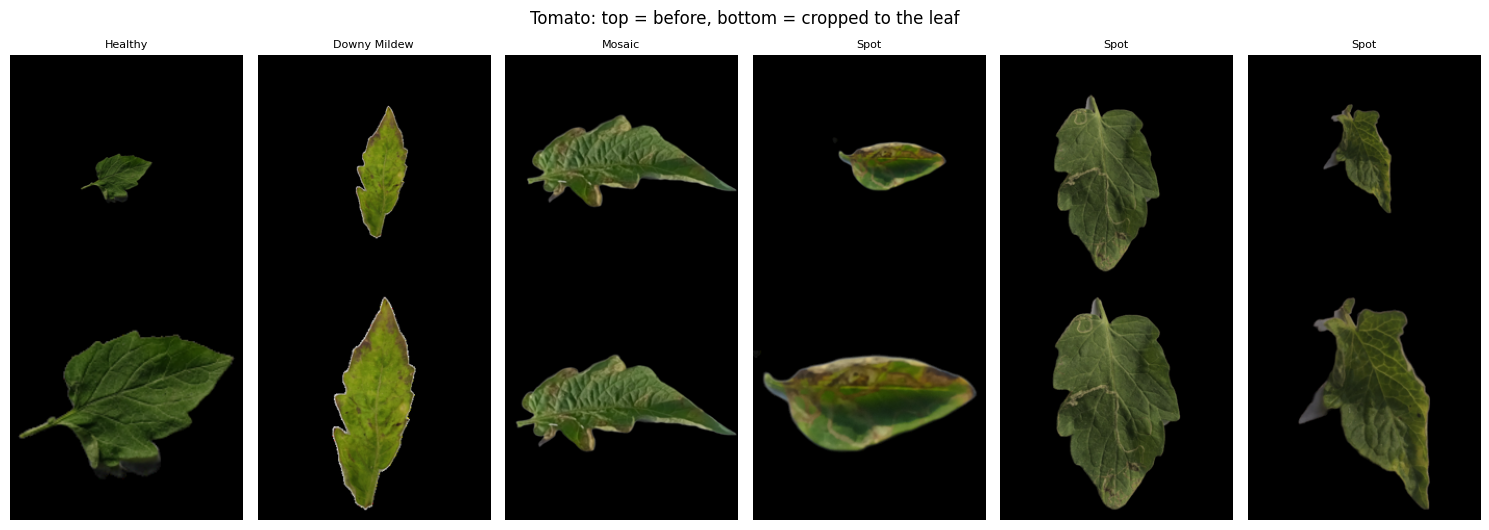

Papaya: the leaf box covers on average 95% of the photo (median 100%, smallest 26%)


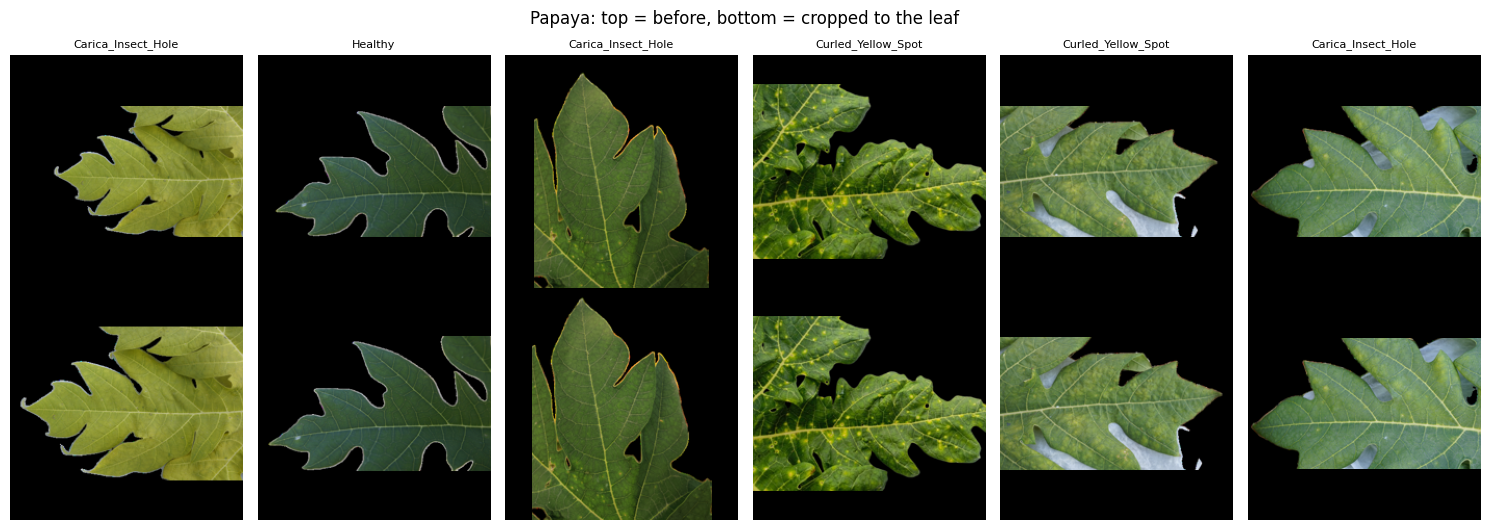

Bottle_Gourd: the leaf box covers on average 70% of the photo (median 72%, smallest 22%)


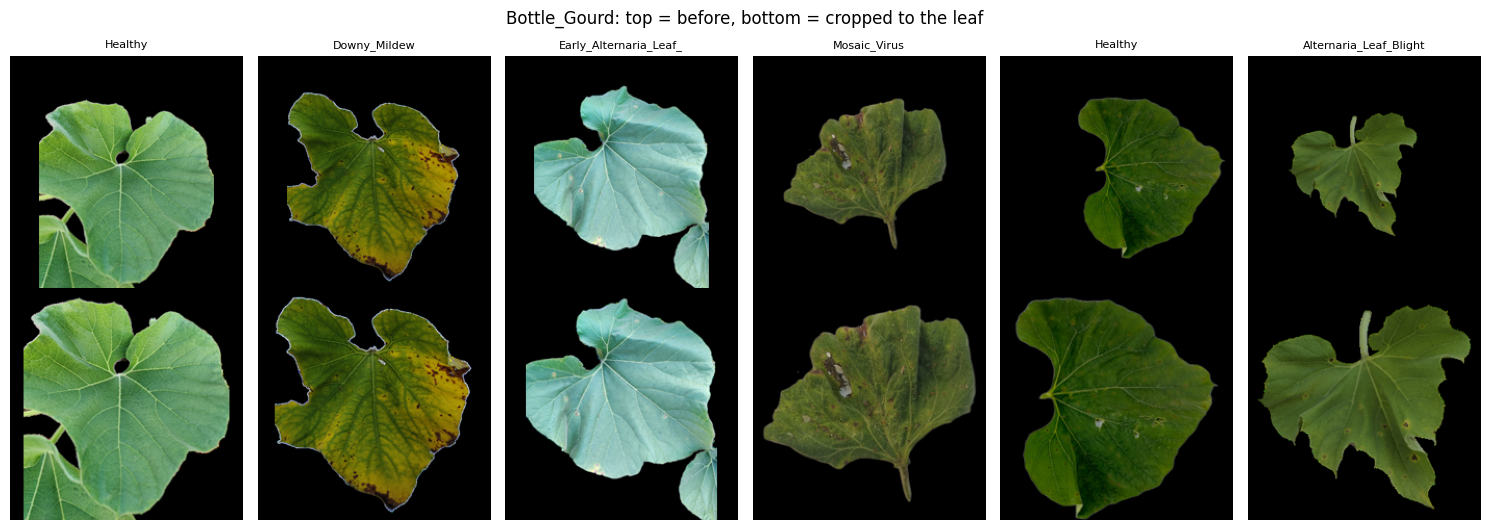

In [11]:
import matplotlib.pyplot as plt
def leaf_box(im, thr=25, margin=0.05):
    # Crop the photo to the leaf: the background is black, so keep the rows/columns that contain leaf pixels.
    a = np.asarray(im)
    m = a.max(axis=2) > thr                                   # pixel brighter than near-black = leaf
    rows, cols = np.where(m.mean(1) > 0.005)[0], np.where(m.mean(0) > 0.005)[0]
    if len(rows) < 10 or len(cols) < 10:
        return im                                             # no clear leaf found: keep the whole photo
    H, W = m.shape
    y1, y2, x1, x2 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
    dy, dx = int(margin * (y2 - y1)), int(margin * (x2 - x1))  # keep a small 5 % border around the leaf
    return im.crop((max(x1 - dx, 0), max(y1 - dy, 0), min(x2 + dx, W), min(y2 + dy, H)))

rng = np.random.default_rng(SEED)
for crop in CROPS:
    d = AV_KEPT[AV_KEPT.crop == crop]
    paths = d.rel_path.sample(min(200, len(d)), random_state=SEED).tolist()
    cover = []
    for p in paths:
        im = Image.open(AV_DIR / p).convert('RGB'); c = leaf_box(im)
        cover.append(c.size[0] * c.size[1] / (im.size[0] * im.size[1]))
    print(f'{crop}: the leaf box covers on average {100*np.mean(cover):.0f}% of the photo '
          f'(median {100*np.median(cover):.0f}%, smallest {100*np.min(cover):.0f}%)')
    fig, ax = plt.subplots(2, 6, figsize=(15, 5.4))
    for j, p in enumerate(rng.choice(paths, 6, replace=False)):
        im = Image.open(AV_DIR / p).convert('RGB')
        ax[0, j].imshow(ImageOps.pad(im, (224, 224))); ax[1, j].imshow(ImageOps.pad(leaf_box(im), (224, 224)))
        ax[0, j].set_title(Path(p).parent.name.replace(crop + '_', '')[:22], fontsize=8)
    for a in ax.flat: a.axis('off')
    fig.suptitle(f'{crop}: top = before, bottom = cropped to the leaf'); plt.tight_layout(); plt.show()

## 6. Training script (as in all runs, plus: optional leaf crop and saved probabilities for the ensemble)

In [12]:
%%writefile /content/train_one.py
# Trains ONE model on the split saved by the notebook, then appends its results. Usage: python train_one.py MODEL
import os, sys, json, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageOps
import tensorflow as tf, keras
from keras import layers
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             cohen_kappa_score, matthews_corrcoef, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

name = sys.argv[1]
OUT = Path(sys.argv[2]); cfg = json.loads((OUT / 'config.json').read_text())
ORIG_DIR, IMG, BATCH, SEED, FOLD = Path(cfg['orig_dir']), cfg['img_size'], cfg['batch'], cfg['seed'], cfg['fold']
d = pd.read_csv(OUT / f"{cfg['crop'].lower()}_split.csv")
CLASSES = sorted(d.label.unique())
y = d.label.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
te = (d.fold == FOLD).to_numpy(); va = (d.fold == (FOLD + 1) % cfg['n_folds']).to_numpy(); tr = ~(te | va)

A, identity = keras.applications, (lambda x: x)
MODELS = {'VGG16': (A.VGG16, A.vgg16.preprocess_input), 'ResNet50': (A.ResNet50, A.resnet50.preprocess_input),
          'DenseNet121': (A.DenseNet121, A.densenet.preprocess_input),
          'InceptionV3': (A.InceptionV3, A.inception_v3.preprocess_input),
          'Xception': (A.Xception, A.xception.preprocess_input),
          'MobileNetV3Large': (A.MobileNetV3Large, identity),
          'EfficientNetV2B0': (A.EfficientNetV2B0, identity), 'ConvNeXtTiny': (A.ConvNeXtTiny, identity)}
keras.mixed_precision.set_global_policy('float32' if name in {'MobileNetV3Large', 'Xception'} else 'mixed_float16')
keras.utils.set_random_seed(SEED + FOLD)

def leaf_box(im, thr=25, margin=0.05):
    # Crop the photo to the leaf: the background is black, so keep the rows/columns that contain leaf pixels.
    a = np.asarray(im)
    m = a.max(axis=2) > thr                                   # pixel brighter than near-black = leaf
    rows, cols = np.where(m.mean(1) > 0.005)[0], np.where(m.mean(0) > 0.005)[0]
    if len(rows) < 10 or len(cols) < 10:
        return im                                             # no clear leaf found: keep the whole photo
    H, W = m.shape
    y1, y2, x1, x2 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
    dy, dx = int(margin * (y2 - y1)), int(margin * (x2 - x1))  # keep a small 5 % border around the leaf
    return im.crop((max(x1 - dx, 0), max(y1 - dy, 0), min(x2 + dx, W), min(y2 + dy, H)))

def load(p):
    im = Image.open(ORIG_DIR / p).convert('RGB')
    if cfg.get('leaf_crop'):
        im = leaf_box(im)
    return np.asarray(ImageOps.pad(im, (IMG, IMG), color=(0, 0, 0)), dtype=np.uint8)
X = np.stack([load(p) for p in d.rel_path])
# Augmentation (training images only). 'basic' = Runs 01b-04; 'moderate' = Run 05.
# No hue/saturation changes: leaf colour is a disease cue (e.g. yellowing in Mosaic).
if cfg.get('augment', 'basic') == 'moderate':
    augment = keras.Sequential([
        layers.RandomFlip('horizontal_and_vertical', dtype='float32'),
        layers.RandomRotation(0.2, dtype='float32'),             # up to +-72 degrees
        layers.RandomZoom(0.2, dtype='float32'),                 # zoom in/out up to 20 %
        layers.RandomTranslation(0.1, 0.1, dtype='float32'),     # shift up to 10 % sideways / up-down
        layers.RandomContrast(0.2, dtype='float32'),
        layers.RandomBrightness(0.15, value_range=(0, 255), dtype='float32')])
else:
    augment = keras.Sequential([layers.RandomFlip('horizontal_and_vertical', dtype='float32'),
                                layers.RandomRotation(0.1, dtype='float32'), layers.RandomZoom(0.1, dtype='float32'),
                                layers.RandomContrast(0.1, dtype='float32')])
ctor, prep = MODELS[name]

# MixUp (training batches only): blend each photo with another random photo from the same batch.
# lam ~ Beta(alpha, alpha) per image; with alpha 0.2 most blends are mostly one photo (lam near 0 or 1).
# The labels are blended with the same weights, e.g. 0.8 Spot + 0.2 Mosaic.
ALPHA = float(cfg.get('mixup_alpha', 0) or 0)
def mixup(a, b):
    n = tf.shape(a)[0]
    g1 = tf.random.gamma([n], ALPHA); g2 = tf.random.gamma([n], ALPHA)
    lam = g1 / (g1 + g2)                                   # Beta(alpha, alpha) sample per image
    j = tf.random.shuffle(tf.range(n))                     # partner image for each image
    lx, ly = tf.reshape(lam, [-1, 1, 1, 1]), tf.reshape(lam, [-1, 1])
    return a * lx + tf.gather(a, j) * (1 - lx), b * ly + tf.gather(b, j) * (1 - ly)

# CutMix (training batches only): cut a random rectangle out of each photo and paste in the same area
# from another photo of the batch. The label is shared by area, e.g. 70 % Spot + 30 % Mosaic.
CUTMIX_ALPHA = float(cfg.get('cutmix_alpha', 0) or 0)
def cutmix(a, b):
    n, H, W = tf.shape(a)[0], tf.shape(a)[1], tf.shape(a)[2]
    g1 = tf.random.gamma([n], CUTMIX_ALPHA); g2 = tf.random.gamma([n], CUTMIX_ALPHA)
    lam = g1 / (g1 + g2)                                   # share of the own photo that is kept
    r = tf.sqrt(1.0 - lam)
    ch = tf.cast(r * tf.cast(H, tf.float32), tf.int32); cw = tf.cast(r * tf.cast(W, tf.float32), tf.int32)
    cy = tf.random.uniform([n], 0, H, dtype=tf.int32); cx = tf.random.uniform([n], 0, W, dtype=tf.int32)
    y1 = tf.clip_by_value(cy - ch // 2, 0, H); y2 = tf.clip_by_value(cy + ch // 2, 0, H)
    x1 = tf.clip_by_value(cx - cw // 2, 0, W); x2 = tf.clip_by_value(cx + cw // 2, 0, W)
    rows, cols = tf.range(H)[None, :], tf.range(W)[None, :]
    in_y = (rows >= y1[:, None]) & (rows < y2[:, None])
    in_x = (cols >= x1[:, None]) & (cols < x2[:, None])
    m = tf.cast(in_y[:, :, None] & in_x[:, None, :], tf.float32)[..., None]
    j = tf.random.shuffle(tf.range(n))
    area = tf.reduce_mean(m, axis=[1, 2, 3])
    keep = tf.reshape(1.0 - area, [-1, 1])
    return a * (1 - m) + tf.gather(a, j) * m, b * keep + tf.gather(b, j) * (1 - keep)

def make_ds(idx, train):
    ds = tf.data.Dataset.from_tensor_slices((X[idx], y[idx]))
    if train:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), tf.one_hot(b, len(CLASSES))),
                             num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
        if ALPHA > 0:
            ds = ds.map(mixup, num_parallel_calls=tf.data.AUTOTUNE)
        if CUTMIX_ALPHA > 0:
            ds = ds.map(cutmix, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.map(lambda a, b: (prep(a), b), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

LOSS = keras.losses.CategoricalCrossentropy(label_smoothing=cfg['label_smoothing'])
base = ctor(include_top=False, weights='imagenet', input_shape=(IMG, IMG, 3)); base.trainable = False
inp = keras.Input((IMG, IMG, 3))
x = layers.GlobalAveragePooling2D()(base(inp, training=False))
model = keras.Model(inp, layers.Dense(len(CLASSES), activation='softmax', dtype='float32')(layers.Dropout(0.3)(x)))
# Training indices. With TARGET_PER_CLASS, every class is topped up to the target by repeating its
# TRAINING images; each repeat gets a different random augmentation every epoch, so it acts as an
# augmented copy. Validation and test images are never copied (no leakage).
rng = np.random.default_rng(SEED)
tr_idx = np.where(tr)[0]
if cfg.get('target_per_class'):
    parts = []
    for c in range(len(CLASSES)):
        own = np.where(tr & (y == c))[0]
        extra = rng.choice(own, max(cfg['target_per_class'] - len(own), 0), replace=True)
        parts += [own, extra]
    tr_idx = np.concatenate(parts)
ds_tr, ds_va, ds_te = make_ds(tr_idx, True), make_ds(np.where(va)[0], False), make_ds(np.where(te)[0], False)
cw = (dict(enumerate(compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=y[tr_idx])))
      if cfg.get('class_weights', True) else None)
opt = lambda lr: keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, clipnorm=1.0)

t0 = time.perf_counter()
model.compile(opt(cfg['head_lr']), LOSS, metrics=['accuracy'])
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['head_epochs'], class_weight=cw, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=3, restore_best_weights=True)])
base.trainable = True
steps = int(np.ceil(len(tr_idx) / BATCH))
sched = keras.optimizers.schedules.CosineDecay(0.0, (cfg['ft_epochs'] - cfg['warmup_epochs']) * steps,
                                               warmup_target=cfg['ft_lr'], warmup_steps=cfg['warmup_epochs'] * steps)
model.compile(opt(sched), LOSS, metrics=['accuracy'])
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['ft_epochs'], class_weight=cw, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_accuracy', mode='max', patience=cfg['ft_patience'],
                                                        restore_best_weights=True),
                          keras.callbacks.TerminateOnNaN()])
minutes = (time.perf_counter() - t0) / 60
p_te, p_va = model.predict(ds_te, verbose=0), model.predict(ds_va, verbose=0)
pred, true, vpred, vtrue = p_te.argmax(1), y[te], p_va.argmax(1), y[va]
(OUT / 'preds').mkdir(exist_ok=True)                       # probabilities are saved for the ensemble (section 10)
np.save(OUT / 'preds' / f'{name}_test_proba.npy', p_te); np.save(OUT / 'preds' / f'{name}_val_proba.npy', p_va)
LAB = range(len(CLASSES))
per = lambda fn, t, p: json.dumps(dict(zip(CLASSES, np.round(fn(t, p, average=None, labels=LAB, zero_division=0), 3).tolist())))

(OUT / 'history').mkdir(exist_ok=True); (OUT / 'preds').mkdir(exist_ok=True)
pd.concat([pd.DataFrame(h1.history).assign(phase='head'), pd.DataFrame(h2.history).assign(phase='finetune')]
          ).to_csv(OUT / 'history' / f'{name}.csv', index=False)
pd.DataFrame({'rel_path': d.rel_path[te].values, 'y_true': true, 'y_pred': pred}).to_csv(OUT / 'preds' / f'{name}.csv', index=False)
best = int(np.nanargmax(h2.history['val_accuracy']))
row = {'run': cfg['run'], 'crop': cfg['crop'], 'model': name, 'fold': FOLD, 'n_train': int(tr.sum()), 'n_train_effective': int(len(tr_idx)), 'augment': cfg.get('augment', 'basic'), 'mixup_alpha': ALPHA, 'cutmix_alpha': CUTMIX_ALPHA, 'n_val': int(va.sum()), 'n_test': int(te.sum()),
       'img_size': IMG, 'label_smoothing': cfg['label_smoothing'],
       'val_accuracy': accuracy_score(vtrue, vpred), 'val_macro_f1': f1_score(vtrue, vpred, average='macro', zero_division=0),
       'accuracy': accuracy_score(true, pred), 'balanced_accuracy': balanced_accuracy_score(true, pred),
       'macro_precision': precision_score(true, pred, average='macro', zero_division=0),
       'macro_recall': recall_score(true, pred, average='macro', zero_division=0),
       'macro_f1': f1_score(true, pred, average='macro', zero_division=0),
       'weighted_f1': f1_score(true, pred, average='weighted', zero_division=0),
       'cohen_kappa': cohen_kappa_score(true, pred), 'mcc': matthews_corrcoef(true, pred),
       'best_val_acc': float(h2.history['val_accuracy'][best]), 'train_acc_at_best': float(h2.history['accuracy'][best]),
       'epochs_head': len(h1.history['loss']), 'epochs_finetune': len(h2.history['loss']),
       'params_M': model.count_params() / 1e6, 'train_minutes': minutes,
       'per_class_precision': per(precision_score, true, pred), 'per_class_recall': per(recall_score, true, pred),
       'per_class_f1': per(f1_score, true, pred), 'val_per_class_f1': per(f1_score, vtrue, vpred),
       'confusion_matrix': json.dumps(confusion_matrix(true, pred, labels=range(len(CLASSES))).tolist())}
res = OUT / 'results.csv'
new = pd.DataFrame([row])
if res.exists():
    new = pd.concat([pd.read_csv(res), new], ignore_index=True)
new.to_csv(res, index=False)
print(f"{name:17s} VAL macroF1 {row['val_macro_f1']:.3f} | test acc {row['accuracy']:.3f} macroF1 {row['macro_f1']:.3f} | "
      f"train_acc {row['train_acc_at_best']:.3f} ({minutes:.1f} min)")

Writing /content/train_one.py


## 7. Train every crop: one separate process per model

In [13]:
def crop_data(crop):
    if crop == 'Rice':
        return RICE_KEPT, RICE_ROOT
    return AV_KEPT[AV_KEPT.crop == crop], AV_DIR

for crop in CROPS:
    d, root = crop_data(crop)
    d = d.sort_values('rel_path').reset_index(drop=True)
    OUT = PROJECT / 'experiments' / crop.lower() / RUN_NAME
    for sub in ['history', 'preds']:
        (OUT / sub).mkdir(parents=True, exist_ok=True)
    d.to_csv(OUT / f'{crop.lower()}_split.csv', index=False)
    te, va = (d.fold == FOLD).to_numpy(), (d.fold == (FOLD + 1) % N_FOLDS).to_numpy()
    tr = ~(te | va)
    target = max(TARGET_PER_CLASS, int(d[tr].label.value_counts().max()))
    cfg = {'run': RUN_NAME, 'note': f'Run 08 for {crop}: Run 05 setting (balanced to {target} per class, no class weights, moderate augmentation) + leaf crop', 'leaf_crop': LEAF_CROP, 'crop': crop,
           'fold': FOLD, 'seed': SEED, 'n_folds': N_FOLDS, 'img_size': IMG_SIZE, 'batch': 32,
           'label_smoothing': LABEL_SMOOTHING, 'target_per_class': target, 'class_weights': USE_CLASS_WEIGHTS,
           'augment': AUGMENT, 'mixup_alpha': MIXUP_ALPHA, 'cutmix_alpha': CUTMIX_ALPHA, 'models': MODEL_NAMES,
           'head_epochs': 15, 'head_lr': 1e-3, 'ft_epochs': 40, 'ft_lr': 3e-5, 'warmup_epochs': 2, 'ft_patience': 10,
           'optimizer': 'AdamW(weight_decay=1e-4, clipnorm=1.0)',
           'early_stopping': 'head: val_loss p3; fine-tune: val_accuracy p10; restore best',
           'augmentation': 'moderate: flip h+v, rotation 0.2, zoom 0.2, translation 0.1, contrast 0.2, brightness 0.15 (train only)',
           'orig_dir': str(root), 'out': str(OUT)}
    (OUT / 'config.json').write_text(json.dumps(cfg, indent=2))
    print(f'\n===== {crop}: {len(d)} images, {d.label.nunique()} classes | train {int((~(te | va)).sum())} / '
          f'validation {int(va.sum())} / test {int(te.sum())} | balanced to {target} per class =====')
    res = OUT / 'results.csv'
    done = set(pd.read_csv(res).model) if res.exists() else set()
    todo = [m for m in MODEL_NAMES if m not in done]
    print(f'{len(done)} finished, {len(todo)} to do')
    for i, name in enumerate(todo, 1):
        p = subprocess.run(['python', '/content/train_one.py', name, str(OUT)], capture_output=True, text=True)
        last = [l for l in p.stdout.strip().splitlines() if l.strip()]
        if p.returncode == 0 and last:
            print(f'[{crop} {i}/{len(todo)}] {last[-1]}   | RAM {psutil.virtual_memory().used/1e9:.1f} GB')
        else:
            print(f'[{crop} {i}/{len(todo)}] {name} FAILED:\n' + p.stderr[-1500:])
print('\nAll crops done.')


===== Tomato: 795 images, 5 classes | train 493 / validation 154 / test 148 | balanced to 300 per class =====
0 finished, 3 to do
[Tomato 1/3] VGG16             VAL macroF1 0.726 | test acc 0.784 macroF1 0.763 | train_acc 0.876 (16.2 min)   | RAM 1.6 GB
[Tomato 2/3] ConvNeXtTiny      VAL macroF1 0.716 | test acc 0.757 macroF1 0.689 | train_acc 0.973 (22.3 min)   | RAM 1.6 GB
[Tomato 3/3] DenseNet121       VAL macroF1 0.722 | test acc 0.750 macroF1 0.714 | train_acc 0.903 (35.2 min)   | RAM 1.6 GB

===== Papaya: 1463 images, 7 classes | train 865 / validation 301 / test 297 | balanced to 300 per class =====
0 finished, 3 to do
[Papaya 1/3] VGG16             VAL macroF1 0.741 | test acc 0.734 macroF1 0.722 | train_acc 0.919 (26.0 min)   | RAM 1.6 GB
[Papaya 2/3] ConvNeXtTiny      VAL macroF1 0.646 | test acc 0.731 macroF1 0.709 | train_acc 0.885 (23.9 min)   | RAM 2.0 GB
[Papaya 3/3] DenseNet121       VAL macroF1 0.689 | test acc 0.727 macroF1 0.717 | train_acc 0.961 (48.2 min)   | RAM 

## 8. Results per crop: validation (for selection) and test fold 0 (development, reported)

In [14]:
pct = lambda df, c: (100 * df[c]).round(1)
for crop in CROPS:
    OUT = PROJECT / 'experiments' / crop.lower() / RUN_NAME
    if not (OUT / 'results.csv').exists():
        continue
    r = pd.read_csv(OUT / 'results.csv').drop_duplicates('model', keep='last').sort_values('val_macro_f1', ascending=False)
    t = pd.DataFrame({'model': r.model, 'VAL macro-F1': pct(r, 'val_macro_f1'), 'VAL acc': pct(r, 'val_accuracy'),
                      'TEST acc': pct(r, 'accuracy'), 'TEST macro-F1': pct(r, 'macro_f1'), 'TEST MCC': pct(r, 'mcc'),
                      'train acc at best': pct(r, 'train_acc_at_best'), 'epochs fine-tune': r.epochs_finetune})
    print(f'\n===== {crop} ({int(r.n_val.iloc[0])} validation / {int(r.n_test.iloc[0])} test images) ====='); display(t)
    f1 = pd.DataFrame({m: json.loads(s) for m, s in zip(r.model, r.per_class_f1)}).T * 100
    print(f'{crop}: test per-class F1 (%)'); display(f1.round(1))
    with pd.ExcelWriter(OUT / f'{crop.lower()}_{RUN_NAME}_results.xlsx') as xw:
        t.to_excel(xw, sheet_name='summary', index=False); f1.round(1).to_excel(xw, sheet_name='test_per_class_f1')


===== Tomato (154 validation / 148 test images) =====


,model,VAL macro-F1,VAL acc,TEST acc,TEST macro-F1,TEST MCC,train acc at best,epochs fine-tune
0,VGG16,72.6,77.3,78.4,76.3,70.6,87.6,18
2,DenseNet121,72.2,78.6,75.0,71.4,66.7,90.3,22
1,ConvNeXtTiny,71.6,79.2,75.7,68.9,67.7,97.3,27


Tomato: test per-class F1 (%)


,Tomato_Downy_Mildew,Tomato_Healthy,Tomato_Mosaic,Tomato_Spot,Tomato_White_Spot
VGG16,82.4,94.0,64.0,74.7,66.7
DenseNet121,72.7,85.1,55.7,80.0,63.6
ConvNeXtTiny,56.0,92.9,60.6,77.6,57.1



===== Papaya (301 validation / 297 test images) =====


,model,VAL macro-F1,VAL acc,TEST acc,TEST macro-F1,TEST MCC,train acc at best,epochs fine-tune
0,VGG16,74.1,75.7,73.4,72.2,68.2,91.9,25
2,DenseNet121,68.9,72.8,72.7,71.7,67.1,96.1,39
1,ConvNeXtTiny,64.6,70.4,73.1,70.9,67.6,88.5,18


... (2 outputs left out)


===== Bottle_Gourd (294 validation / 302 test images) =====


,model,VAL macro-F1,VAL acc,TEST acc,TEST macro-F1,TEST MCC,train acc at best,epochs fine-tune
0,VGG16,75.7,79.3,80.8,77.9,77.0,89.7,23
1,ConvNeXtTiny,75.0,77.9,82.8,79.5,79.5,84.5,16
2,DenseNet121,67.8,73.5,76.5,70.8,72.3,72.2,14


Bottle_Gourd: test per-class F1 (%)


,Bottle_Gourd_Alternaria_Leaf_Blight,Bottle_Gourd_Anthracnose,Bottle_Gourd_Downy_Mildew,Bottle_Gourd_Early_Alternaria_Leaf_Blight,Bottle_Gourd_Fungal_Damage_Leaf,Bottle_Gourd_Healthy,Bottle_Gourd_Mosaic_Virus
VGG16,81.2,82.1,84.5,64.8,62.5,90.1,80.0
ConvNeXtTiny,86.3,80.0,83.5,67.6,63.2,89.5,86.4
DenseNet121,83.0,77.3,81.3,43.1,50.0,81.2,79.7


## 9. Did cropping to the leaf help? Run 05 vs Run 08, every crop

In [15]:
BASE = {'Tomato': 'run05_balanced300_moderateaug', 'Papaya': 'run05_balanced_moderateaug', 'Bottle_Gourd': 'run05_balanced_moderateaug'}
NEW  = {c: RUN_NAME for c in BASE}
def load(crop, run):
    f = PROJECT / 'experiments' / crop.lower() / run / 'results.csv'
    return pd.read_csv(f).drop_duplicates('model', keep='last').set_index('model') if f.exists() else None

summary, per_model = [], {}
for crop in BASE:
    b, n = load(crop, BASE[crop]), load(crop, NEW[crop])
    if b is None or n is None:
        print('missing results for', crop); continue
    ms = [m for m in MODEL_NAMES if m in b.index and m in n.index]
    vb, vn = 100 * b.loc[ms, 'val_macro_f1'], 100 * n.loc[ms, 'val_macro_f1']
    per_model[crop] = pd.DataFrame({'Run 05': vb.round(1), 'Run 08 leaf crop': vn.round(1), 'change': (vn - vb).round(1)})
    summary.append({'crop': crop, 'models': len(ms),
                    'VAL macro-F1 Run 05': round(vb.mean(), 1), 'VAL macro-F1 Run 08': round(vn.mean(), 1),
                    'change': round(vn.mean() - vb.mean(), 1), 'models improved': f'{int((vn > vb).sum())} of {len(ms)}',
                    'TEST macro-F1 Run 05': round(100 * b.loc[ms, 'macro_f1'].mean(), 1),
                    'TEST macro-F1 Run 08': round(100 * n.loc[ms, 'macro_f1'].mean(), 1)})
summary = pd.DataFrame(summary).set_index('crop')
print('Mean of the same models, Run 05 vs Run 08 (leaf crop):'); display(summary)
for crop, t in per_model.items():
    print(f'\n{crop}: validation macro-F1 per model'); display(t)
with pd.ExcelWriter(PROJECT / 'experiments' / 'run08_leafcrop_all_crops.xlsx') as xw:
    summary.to_excel(xw, sheet_name='summary')
    for crop, t in per_model.items():
        t.to_excel(xw, sheet_name=crop[:31])
print('Saved', PROJECT / 'experiments' / 'run08_leafcrop_all_crops.xlsx')

Mean of the same models, Run 05 vs Run 08 (leaf crop):


,models,VAL macro-F1 Run 05,VAL macro-F1 Run 08,change,models improved,TEST macro-F1 Run 05,TEST macro-F1 Run 08
crop,,,,,,,
Tomato,3,73.4,72.2,-1.3,0 of 3,71.9,72.2
Papaya,3,69.9,69.2,-0.7,1 of 3,68.6,71.6
Bottle_Gourd,3,69.3,72.8,3.5,3 of 3,73.5,76.1



Tomato: validation macro-F1 per model


,Run 05,Run 08 leaf crop,change
model,,,
VGG16,73.8,72.6,-1.2
ConvNeXtTiny,72.8,71.6,-1.2
DenseNet121,73.6,72.2,-1.4



Papaya: validation macro-F1 per model


,Run 05,Run 08 leaf crop,change
model,,,
VGG16,74.2,74.1,-0.1
ConvNeXtTiny,67.6,64.6,-2.9
DenseNet121,67.9,68.9,1.0



Bottle_Gourd: validation macro-F1 per model


,Run 05,Run 08 leaf crop,change
model,,,
VGG16,70.4,75.7,5.3
ConvNeXtTiny,70.6,75.0,4.4
DenseNet121,66.9,67.8,1.0


Saved /content/drive/MyDrive/thesis/experiments/run08_leafcrop_all_crops.xlsx


## 10. Ensemble: average the probabilities of the 3 models

In [16]:
from sklearn.metrics import f1_score, accuracy_score
rows = []
for crop in CROPS:
    OUT = PROJECT / 'experiments' / crop.lower() / RUN_NAME
    d = pd.read_csv(OUT / f'{crop.lower()}_split.csv')
    classes = sorted(d.label.unique()); y = d.label.map({c: i for i, c in enumerate(classes)}).to_numpy()
    yv, yt = y[(d.fold == (FOLD + 1) % N_FOLDS).to_numpy()], y[(d.fold == FOLD).to_numpy()]
    ms = [m for m in MODEL_NAMES if (OUT / 'preds' / f'{m}_val_proba.npy').exists()]
    if len(ms) < 2:
        continue
    pv = {m: np.load(OUT / 'preds' / f'{m}_val_proba.npy') for m in ms}
    pt = {m: np.load(OUT / 'preds' / f'{m}_test_proba.npy') for m in ms}
    single = {m: f1_score(yv, pv[m].argmax(1), average='macro') for m in ms}
    best = max(single, key=single.get)
    ev, et = np.mean([pv[m] for m in ms], 0).argmax(1), np.mean([pt[m] for m in ms], 0).argmax(1)
    rows.append({'crop': crop, 'best single model (val)': best,
                 'VAL macro-F1 best single': round(100 * single[best], 1),
                 'VAL macro-F1 ensemble': round(100 * f1_score(yv, ev, average='macro'), 1),
                 'TEST macro-F1 best single': round(100 * f1_score(yt, pt[best].argmax(1), average='macro'), 1),
                 'TEST macro-F1 ensemble': round(100 * f1_score(yt, et, average='macro'), 1),
                 'TEST acc ensemble': round(100 * accuracy_score(yt, et), 1)})
ens = pd.DataFrame(rows).set_index('crop')
print('Ensemble of', MODEL_NAMES); display(ens)
ens.to_csv(PROJECT / 'experiments' / 'run08_ensemble.csv')

Ensemble of ['VGG16', 'ConvNeXtTiny', 'DenseNet121']


,best single model (val),VAL macro-F1 best single,VAL macro-F1 ensemble,TEST macro-F1 best single,TEST macro-F1 ensemble,TEST acc ensemble
crop,,,,,,
Tomato,VGG16,72.6,74.6,76.3,71.0,75.7
Papaya,VGG16,74.1,73.4,72.2,74.2,75.1
Bottle_Gourd,VGG16,75.7,75.9,77.9,81.8,84.1
